<a href="https://colab.research.google.com/github/mamoo9811/Student-Performance-EDA-/blob/main/Student_Performance_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Student Performance in Exams**

Author: **MAHMOUD SALEH**

### Table of Contents

1. Project Overview
2. Load and Inspect Data
3. Clean Data
4. Data Preparation
5. Statistical Analysis of Math Score
6. Univariate Analysis
7. Multivariate Analysis
8. Hypothesis Testing
9. Conclusions

-------------------------------------------------------------------------------------------------------------------------------------------------

# **Project Overview**

### Project Background
This project aims to explore the factors associated with student academic performance in examinations. The analysis focuses on understanding how student characteristics, parental education, lunch type, and test preparation may relate to examination results.

### Project Objective
The main objective is to analyze student performance, with particular emphasis on mathematics scores, using exploratory data analysis and statistical methods.

### Stakeholder
School administrators and teachers, who can use the findings to better understand student performance and identify areas where additional academic support may be needed.

### Main Feature
Math Score.

### Tools and Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy, Google Colab, and GitHub.

### Key Research Questions
1. Is the math score normally distributed?
2. Does test preparation affect exam scores?
3. Is there a relationship between reading and writing scores?
4. Which subject has the greatest variation?
5. Does parental education relate to student performance?

### Expected Outcome
A complete exploratory data analysis project, including data cleaning, statistical analysis, visualizations, and evidence-based conclusions to support school decision-making.

---------------------------------------------------------------------

# **Load and Inspect Data**

In [147]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
data = "https://raw.githubusercontent.com/mamoo9811/Student-Performance-EDA-/main/data/StudentsPerformance.csv"
df1 = pd.read_csv(data)
df = df1
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [148]:
df.tail(2)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


In [149]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [150]:
df.shape

(1000, 8)

### Column Descriptions:
0.   gender :  The gender of each student (male or female)

1.   race/ethnicity : The ethnic group to which each student belongs

2.   parental level of education : The highest educational level attained by the student's parents

3.   lunch : The type of lunch program received by the student (standard or free/reduced)

4.   test preparation course : Indicates whether the student completed a test preparation course

5.   math score : The student's score in the mathematics examination

6.   reading score : The student's score in the reading examination

7.   writing score : The student's score in the writing examination

In [151]:
df.dtypes

,0
gender,object
race/ethnicity,object
parental level of education,object
lunch,object
test preparation course,object
math score,int64
reading score,int64
writing score,int64


# **Clean Data**


In [152]:
nul_sum = df.isna().sum()
nul_sum

,0
gender,0
race/ethnicity,0
parental level of education,0
lunch,0
test preparation course,0
math score,0
reading score,0
writing score,0


In [153]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [154]:
df.select_dtypes(include='number').min()

,0
math score,0
reading score,17
writing score,10


In [155]:
df.select_dtypes(include='number').max()

,0
math score,100
reading score,100
writing score,100


In [156]:
Q1 = df.select_dtypes(include='number').quantile(0.25)
Q3 = df.select_dtypes(include='number').quantile(0.75)
IQR = Q3 - Q1
outliers = (
    (df.select_dtypes(include='number') < (Q1 - 1.5 * IQR)) |
    (df.select_dtypes(include='number') > (Q3 + 1.5 * IQR))
)
outliers.sum()

,0
math score,8
reading score,6
writing score,5


In [157]:
cat_col = df.select_dtypes(include='object')
for col in cat_col.columns:
    print("\n", col)
    print(df[col].value_counts(dropna=False))


 gender
gender
female    518
male      482
Name: count, dtype: int64

 race/ethnicity
race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64

 parental level of education
parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64

 lunch
lunch
standard        645
free/reduced    355
Name: count, dtype: int64

 test preparation course
test preparation course
none         642
completed    358
Name: count, dtype: int64


In [158]:
df['parental level of education'] = df['parental level of education'].replace({
    'some high school': 'high school'
})

df['parental level of education'].value_counts()

,count
parental level of education,
high school,375
some college,226
associate's degree,222
bachelor's degree,118
master's degree,59


In [159]:
df['parental level of education'] = df['parental level of education'].replace({
    'high school': 'high school or some high school'
})
df['parental level of education'].value_counts()

,count
parental level of education,
high school or some high school,375
some college,226
associate's degree,222
bachelor's degree,118
master's degree,59


In [160]:
df['test preparation course'] = df['test preparation course'].replace({
    'none': 'not completed'
})
df['test preparation course'].value_counts()

,count
test preparation course,
not completed,642
completed,358


In [161]:
for col in cat_col.columns:
    print("\n", col)
    print(df[col].value_counts(dropna=False))


 gender
gender
female    518
male      482
Name: count, dtype: int64

 race/ethnicity
race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64

 parental level of education
parental level of education
high school or some high school    375
some college                       226
associate's degree                 222
bachelor's degree                  118
master's degree                     59
Name: count, dtype: int64

 lunch
lunch
standard        645
free/reduced    355
Name: count, dtype: int64

 test preparation course
test preparation course
not completed    642
completed        358
Name: count, dtype: int64


In [162]:
df.duplicated().sum()

np.int64(0)

In [163]:
df[df.duplicated(keep=False)]

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score


In [164]:
df.columns = (df.columns
              .str.strip()
              .str.title()
              .str.replace(' ', '_')
              .str.replace('/', '_', regex=False))

In [165]:
df.columns

Index(['Gender', 'Race_Ethnicity', 'Parental_Level_Of_Education', 'Lunch',
       'Test_Preparation_Course', 'Math_Score', 'Reading_Score',
       'Writing_Score'],
      dtype='object')

### Analysis Questions

•	**Which columns are numerical, and which are categorical?**

Numerical Columns: Math_Score, Reading_Score, Writing_Score

 Categorical Columns: Gender, Race_Ethnicity, Parental_Level_Of_Education, Lunch, Test_Preparation_Course


•	**Did you find missing values , duplicates , or inconsistent categories?**

No missing values or fully duplicated rows were found in the dataset and no inconsistent categorical values or extra spaces were detected


•**Are there outliers in the scores? Should they be removed or kept? Why?**

The IQR method identified 8 outliers in Math_Score  ,6 in Reading_Score and 5 in Writing_Score and all identified scores were within the valid range of 0–100 ,the outliers were retained because they may represent genuine student performance rather than data entry errors

### Data Quality Conclusion

The dataset is clean and ready for analysis. There are no missing values or duplicate rows. The data types are correct, and there are no invalid scores or category errors.

The IQR method found 8 outliers in Math_Score, 6 in Reading_Score, and 5 in Writing_Score. All scores are between 0 and 100, so we kept these values.

Finally, we changed the column names to make them easier to use. The dataset is now ready for the next step.

---------------------------------------------------------------------

# **Data Preparation**

In [166]:
num_col = df.select_dtypes(include=['int64', 'float64'])
num_col
#and also we have tha Categorical up there names cat_col

,Math_Score,Reading_Score,Writing_Score
0,72,72,74
1,69,90,88
2,90,95,93
3,47,57,44
4,76,78,75
...,...,...,...
995,88,99,95
996,62,55,55
997,59,71,65
998,68,78,77


In [167]:
df['Total_Score'] = (
    df['Math_Score'] +
    df['Reading_Score'] +
    df['Writing_Score']
)
df['Total_Score']

,Total_Score
0,218
1,247
2,278
3,148
4,229
...,...
995,282
996,172
997,195
998,223


In [168]:
mean_ofs = df[['Math_Score', 'Reading_Score', 'Writing_Score']].mean(axis=1)
df['Average_Score'] = mean_ofs
df['Average_Score']

,Average_Score
0,72.666667
1,82.333333
2,92.666667
3,49.333333
4,76.333333
...,...
995,94.000000
996,57.333333
997,65.000000
998,74.333333


In [169]:
df['Pass_Math'] = df['Math_Score'] >= 50
df['Pass_Math']

,Pass_Math
0,True
1,True
2,True
3,False
4,True
...,...
995,True
996,True
997,True
998,True


In [170]:
df['Performance_Level'] = 'Medium'

df.loc[df['Average_Score'] < 50, 'Performance_Level'] = 'Low'

df.loc[df['Average_Score'] >= 80, 'Performance_Level'] = 'High'
df['Performance_Level']

,Performance_Level
0,Medium
1,High
2,High
3,Low
4,Medium
...,...
995,High
996,Medium
997,Medium
998,Medium


In [171]:
df['Performance_Level'].value_counts()

,count
Performance_Level,
Medium,699
High,198
Low,103


In [172]:
df.shape

(1000, 12)

In [173]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Gender                       1000 non-null   object 
 1   Race_Ethnicity               1000 non-null   object 
 2   Parental_Level_Of_Education  1000 non-null   object 
 3   Lunch                        1000 non-null   object 
 4   Test_Preparation_Course      1000 non-null   object 
 5   Math_Score                   1000 non-null   int64  
 6   Reading_Score                1000 non-null   int64  
 7   Writing_Score                1000 non-null   int64  
 8   Total_Score                  1000 non-null   int64  
 9   Average_Score                1000 non-null   float64
 10  Pass_Math                    1000 non-null   bool   
 11  Performance_Level            1000 non-null   object 
dtypes: bool(1), float64(1), int64(4), object(6)
memory usage: 87.0+ KB


In [174]:
df.describe()

,Math_Score,Reading_Score,Writing_Score,Total_Score,Average_Score
count,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000,203.312000,67.770667
std,15.16308,14.600192,15.195657,42.771978,14.257326
min,0.00000,17.000000,10.000000,27.000000,9.000000
25%,57.00000,59.000000,57.750000,175.000000,58.333333
50%,66.00000,70.000000,69.000000,205.000000,68.333333
75%,77.00000,79.000000,79.000000,233.000000,77.666667
max,100.00000,100.000000,100.000000,300.000000,100.000000


In [175]:
df.head()

,Gender,Race_Ethnicity,Parental_Level_Of_Education,Lunch,Test_Preparation_Course,Math_Score,Reading_Score,Writing_Score,Total_Score,Average_Score,Pass_Math,Performance_Level
0,female,group B,bachelor's degree,standard,not completed,72,72,74,218,72.666667,True,Medium
1,female,group C,some college,standard,completed,69,90,88,247,82.333333,True,High
2,female,group B,master's degree,standard,not completed,90,95,93,278,92.666667,True,High
3,male,group A,associate's degree,free/reduced,not completed,47,57,44,148,49.333333,False,Low
4,male,group C,some college,standard,not completed,76,78,75,229,76.333333,True,Medium


### Data Preparation Decisions

The numerical and categorical features were separated based on their data types

Four new columns were created:

- **Total_Score:** The sum of the three exam scores
- **Average_Score:** The average score of each student
- **Pass_Math:** Shows if a student passed math with a score of 50 or higher
- **Performance_Level:** Groups students into Low, Medium, and High levels based on their average scores

These new columns help us understand student performance and make the analysis easier

the dataset was checked to make sure it was ready for statistical analysis




---------------------------------------------------------------------

# **Statistical Analysis: Math Score**


In [176]:
df['Math_Score'].describe()

,Math_Score
count,1000.00000
mean,66.08900
std,15.16308
min,0.00000
25%,57.00000
50%,66.00000
75%,77.00000
max,100.00000


In [177]:
mean_m = df['Math_Score'].mean()
med_m = df['Math_Score'].median()
mod_m = df['Math_Score'].mode()
print(mean_m,med_m,'\n',mod_m)

66.089 66.0 
 0    65
Name: Math_Score, dtype: int64


In [178]:
Variance = df['Math_Score'].var()
std = df['Math_Score'].std()
print(Variance , std)

229.91899799799847 15.163080096009468


In [179]:
skeww = df['Math_Score'].skew()
Kurtosis = df['Math_Score'].kurtosis()
print(skeww,Kurtosis)

-0.27893514909431694 0.27496405752108455


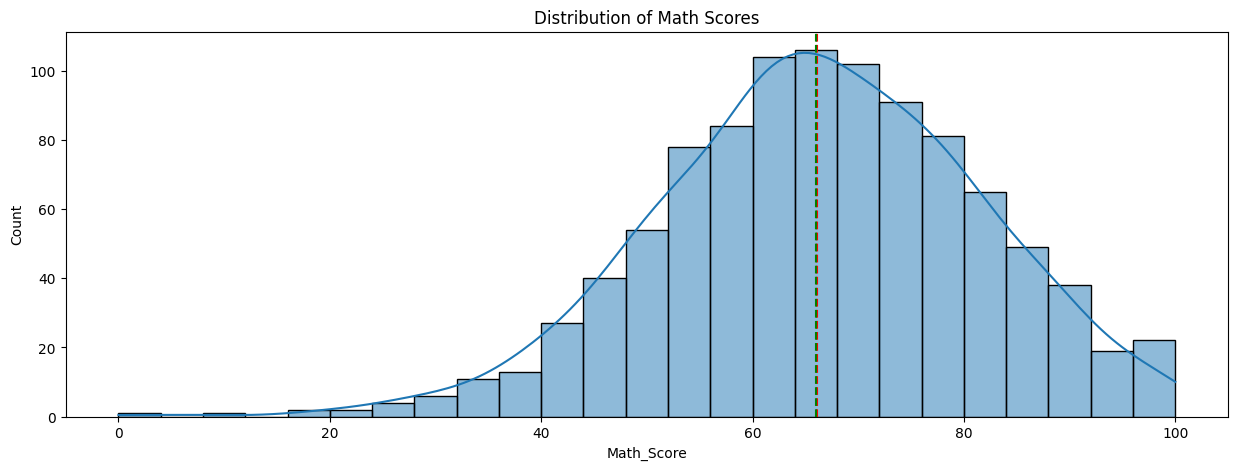

In [180]:
fig , ax = plt.subplots(figsize=(15,5))
sns.histplot(df['Math_Score'], kde=True)
ax.axvline(mean_m, color='red', linestyle='--', label='Mean')
ax.axvline(med_m, color='green', linestyle='--', label='Median')
plt.title('Distribution of Math Scores')
plt.savefig('images/math_distribution.png', dpi=300, bbox_inches='tight')

Text(0.5, 1.0, 'Cumulative Distribution of Math Scores')

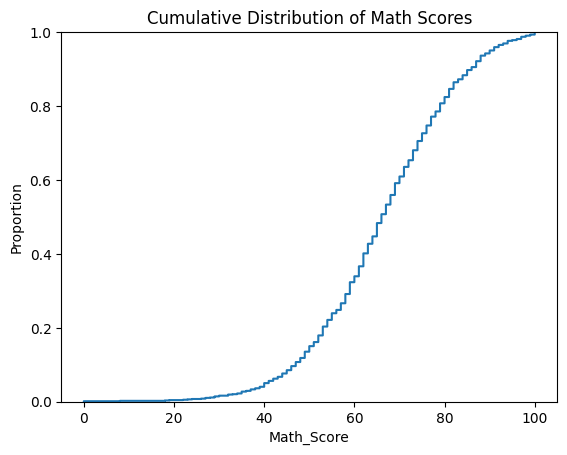

In [181]:
sns.ecdfplot(data=df, x='Math_Score')
plt.title('Cumulative Distribution of Math Scores')

Text(0.5, 1.0, 'Boxplot of Math Scores')

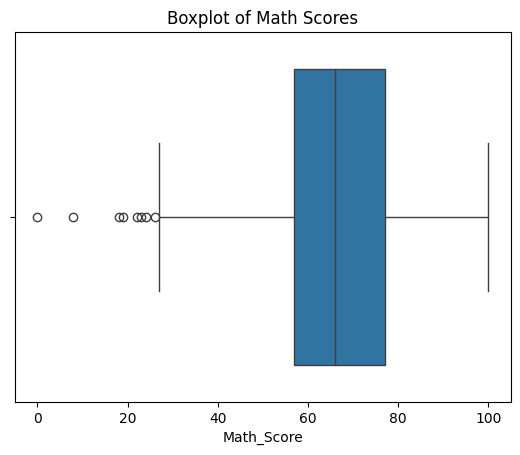

In [182]:
sns.boxplot(x=df['Math_Score'])
plt.title('Boxplot of Math Scores')

In [183]:
result = stats.normaltest(df['Math_Score'])
print(result)
result.pvalue < 0.05                                                         #its  NOT normal

NormaltestResult(statistic=np.float64(15.408960513931822), pvalue=np.float64(0.00045080293869937836))


np.True_

### Analysis Questions

**1. Are the mean and median close to each other? What does that suggest?**

Yes, the mean 66.09 and median 66 are very close This suggests that the distribution is almost symmetric

**2. Is math score positively or negatively skewed?**

negatively skewed because the skewness value is -0.279

**3. What does the kurtosis indicate about extreme scores?**

This indicates slightly heavier tails than a normal distribution

**4. What does the CDF tell you?**

the percentage of students who scored below or equal to each score

**5. Based on the plots, the skewness, the kurtosis, and the normality test, is math score approximately normally distributed?**

The histogram looks almost like a normal distribution but the normality test gives a p-value below 0.05 so math scores are not normally distributed according to the statistical test.

---------------------------------------------------------------------

# **Univariate Analysis**

In [184]:
df.head()

,Gender,Race_Ethnicity,Parental_Level_Of_Education,Lunch,Test_Preparation_Course,Math_Score,Reading_Score,Writing_Score,Total_Score,Average_Score,Pass_Math,Performance_Level
0,female,group B,bachelor's degree,standard,not completed,72,72,74,218,72.666667,True,Medium
1,female,group C,some college,standard,completed,69,90,88,247,82.333333,True,High
2,female,group B,master's degree,standard,not completed,90,95,93,278,92.666667,True,High
3,male,group A,associate's degree,free/reduced,not completed,47,57,44,148,49.333333,False,Low
4,male,group C,some college,standard,not completed,76,78,75,229,76.333333,True,Medium


Text(0.5, 1.0, 'Distribution of Reading Scores')

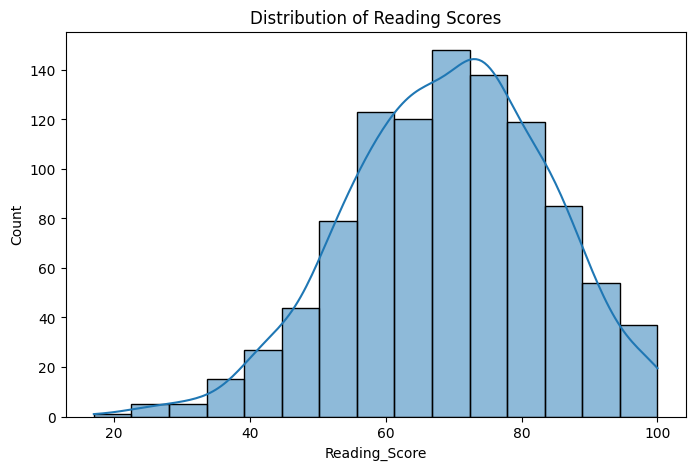

In [185]:
plt.figure(figsize=(8, 5))

sns.histplot(df['Reading_Score'], bins=15, kde=True)
plt.title('Distribution of Reading Scores')

this is the reading scores are distributed among students most students have scores in the middle range, while fewer students have very low or very high scores

Text(0.5, 1.0, 'Distribution of Writing Scores')

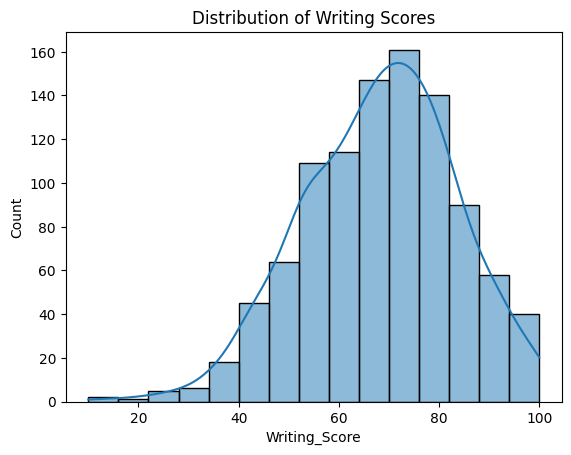

In [208]:
sns.histplot(df['Writing_Score'], bins=15, kde=True)
plt.title('Distribution of Writing Scores')

The histogram shows that most students have writing scores between 60 and 85, the highest number of students scored around 70–75 and very few students have low scores

Text(0.5, 1.0, 'Distribution of Math Scores')

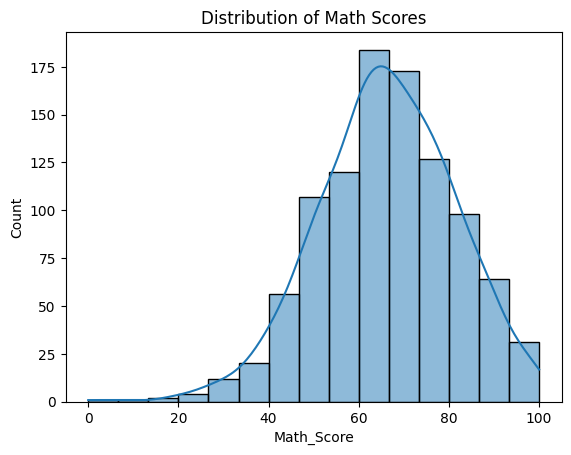

In [209]:
sns.histplot(df['Math_Score'], bins=15, kde=True)
plt.title('Distribution of Math Scores')

The histogram shows that most students have math scores between 50 and 80  but the highest number of students scored around 60–70 and Very few students have very low or very high scores

Text(0.5, 1.0, 'Boxplot of Writing Scores')

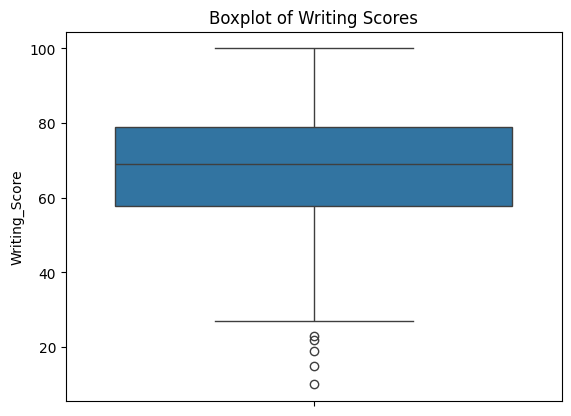

In [188]:
sns.boxplot(y=df['Writing_Score'])
plt.title('Boxplot of Writing Scores')

The boxplot shows the spread of writing scores it also shows the median, the quartiles and some possible outliers

Text(0, 0.5, 'Average Score')

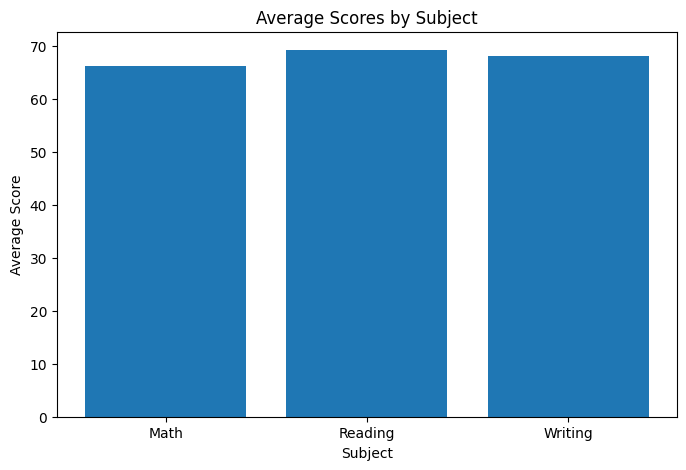

In [189]:
mean_m
mean_r = df['Reading_Score'].mean()
mean_w = df['Writing_Score'].mean()

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(['Math', 'Reading', 'Writing'], [mean_m, mean_r, mean_w])
ax.set_title('Average Scores by Subject')
ax.set_xlabel('Subject')
ax.set_ylabel('Average Score')

The bar chart compares the average scores in the three subjects it helps us see which subject has the highest and lowest average

Text(0.5, 1.0, 'Students by Test Preparation Course')

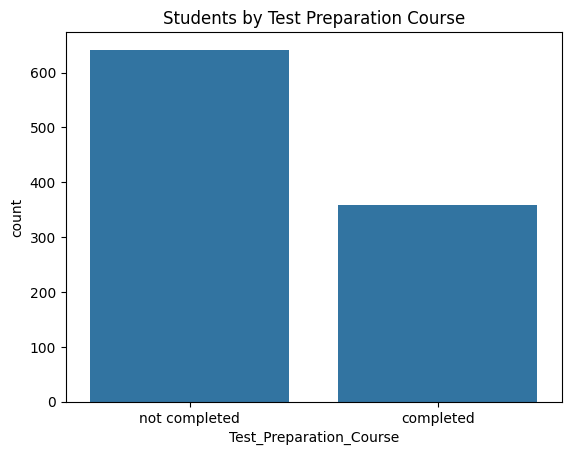

In [190]:
sns.countplot(data=df, x='Test_Preparation_Course')
plt.title('Students by Test Preparation Course')

The countplot shows the number of students who completed the test preparation course and those who did not

([0, 1, 2, 3, 4],
 [Text(0, 0, "bachelor's degree"),
  Text(1, 0, 'some college'),
  Text(2, 0, "master's degree"),
  Text(3, 0, "associate's degree"),
  Text(4, 0, 'high school or some high school')])

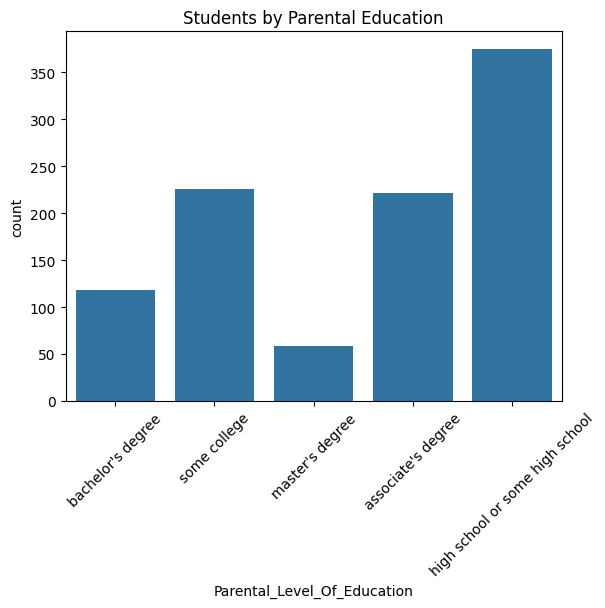

In [210]:
sns.countplot(data=df, x='Parental_Level_Of_Education')
plt.title('Students by Parental Education')
plt.xticks(rotation=45)

The countplot shows that high school or some high school is the most common parental education level so the master's degree is the least common level this shows that the number of students is different across education groups

Text(0.5, 1.0, 'Students by Gender')

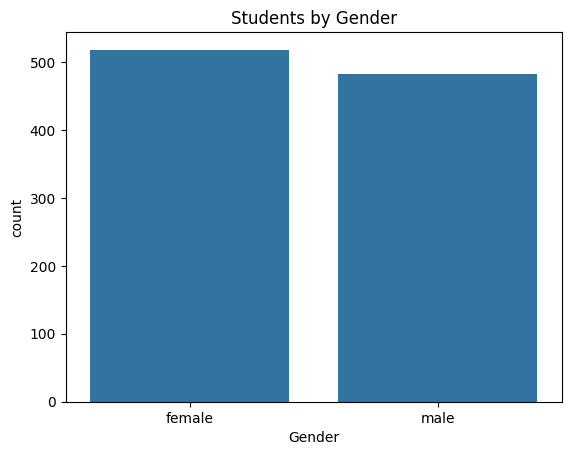

In [211]:
sns.countplot(data=df, x='Gender')
plt.title('Students by Gender')

The countplot shows that the number of female students is slightly higher than male students so the numbers are quite close so the gender groups are almost balanced

In [193]:
print("Math:", df['Math_Score'].std())

print("Reading:", df['Reading_Score'].std())

print("Writing:", df['Writing_Score'].std())

Math: 15.163080096009468
Reading: 14.60019193725222
Writing: 15.195657010869642


### Analysis Questions

**1. Which subject has the greatest variation?**

Writing has the greatest variation among the three subjects because it has the highest standard deviation sp this means that writing scores are more spread out than math and reading scores.

**2. How many students completed the test preparation course?**

 358 students completed the test preparation course

**3. Which parental education level is the most common?**

High school or some high school

**4. Are the categories balanced, or are some groups much smaller than others?**

The gender groups are almost balanced, with slightly more female students than male students but the parental education groups are not balanced and Some groups such as master's degree are much smaller than others the test preparation groups are also different in size

---------------------------------------------------------------------

# **Multivariate Analysis**

In [194]:
df.head()

,Gender,Race_Ethnicity,Parental_Level_Of_Education,Lunch,Test_Preparation_Course,Math_Score,Reading_Score,Writing_Score,Total_Score,Average_Score,Pass_Math,Performance_Level
0,female,group B,bachelor's degree,standard,not completed,72,72,74,218,72.666667,True,Medium
1,female,group C,some college,standard,completed,69,90,88,247,82.333333,True,High
2,female,group B,master's degree,standard,not completed,90,95,93,278,92.666667,True,High
3,male,group A,associate's degree,free/reduced,not completed,47,57,44,148,49.333333,False,Low
4,male,group C,some college,standard,not completed,76,78,75,229,76.333333,True,Medium


Text(0.5, 1.0, 'Relationship Between Reading and Writing Scores')

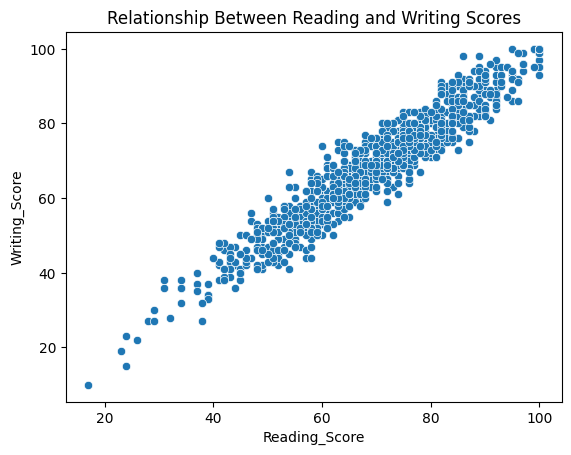

In [195]:
sns.scatterplot(data=df, x='Reading_Score', y='Writing_Score')
plt.title('Relationship Between Reading and Writing Scores')

The scatter plot shows a strong positive relationship between reading and writing scores students with higher reading scores usually have higher writing scores

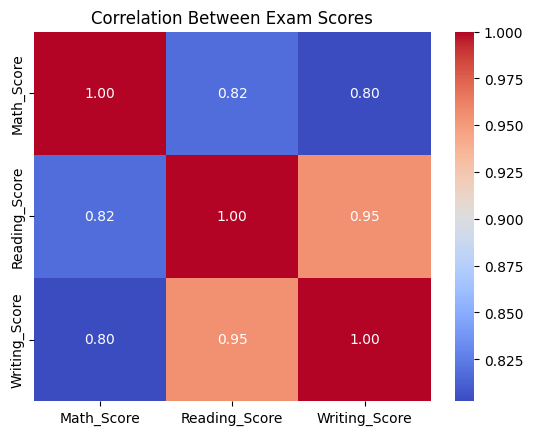

In [196]:
correlation = df[
    ['Math_Score', 'Reading_Score', 'Writing_Score']
].corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Between Exam Scores')
plt.savefig('images/insight_1.png', dpi=300, bbox_inches='tight')

The heatmap shows positive relationships between all three subjects so Reading and writing have the strongest relationship  with a correlation of 0.95and Math is also positively related to reading (0.82) and writing (0.80)

In [197]:
df.groupby('Parental_Level_Of_Education')[
    ['Math_Score', 'Reading_Score', 'Writing_Score']
].mean()

,Math_Score,Reading_Score,Writing_Score
Parental_Level_Of_Education,,,
associate's degree,67.882883,70.927928,69.896396
bachelor's degree,69.389831,73.000000,73.381356
high school or some high school,62.786667,65.770667,63.613333
master's degree,69.745763,75.372881,75.677966
some college,67.128319,69.460177,68.840708


Students whose parents have a master's degree have the highest average scores in all three subjects and the high school or some high school group has the lowest average scores

In [198]:
df.groupby('Gender')[
    ['Math_Score', 'Reading_Score', 'Writing_Score']
].mean()

,Math_Score,Reading_Score,Writing_Score
Gender,,,
female,63.633205,72.608108,72.467181
male,68.728216,65.473029,63.311203


Male students have a higher average score in math so female students have higher average scores in reading and writing

In [199]:
df.groupby('Lunch')[
    ['Math_Score', 'Reading_Score', 'Writing_Score']
].mean()

,Math_Score,Reading_Score,Writing_Score
Lunch,,,
free/reduced,58.921127,64.653521,63.022535
standard,70.034109,71.654264,70.823256


Students with standard lunch have higher average scores in math, reading, and writing than students with free or reduced lunch

Text(0.5, 1.0, 'Math Scores by Test Preparation Course')

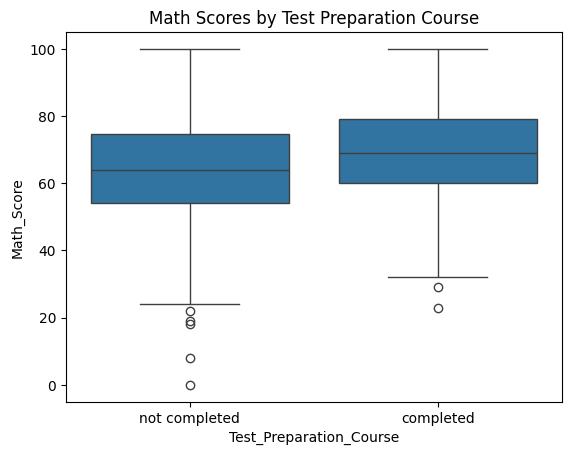

In [200]:
sns.boxplot(data=df, x='Test_Preparation_Course', y='Math_Score')
plt.title('Math Scores by Test Preparation Course')

The boxplot shows that students who completed the test preparation course have higher math scores than students who did not complete it so this suggests that test preparation is related to better math performance.

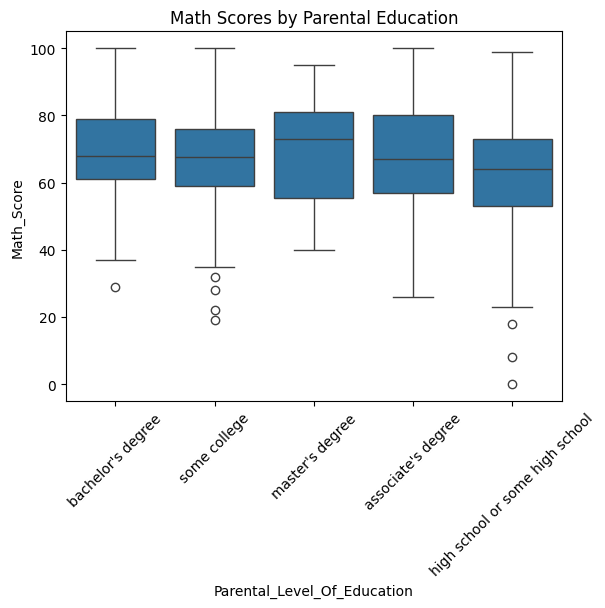

In [201]:
sns.boxplot(data=df, x='Parental_Level_Of_Education', y='Math_Score')
plt.title('Math Scores by Parental Education')
plt.xticks(rotation=45)
plt.savefig('images/insight_2.png', dpi=300, bbox_inches='tight')

The boxplot shows differences in math scores between parental education groups  students whose parents have a master's degree have a higher median scoreand students in the high school or some high school group have a lower median score

Text(0.5, 1.0, 'Math Scores by Lunch Type')

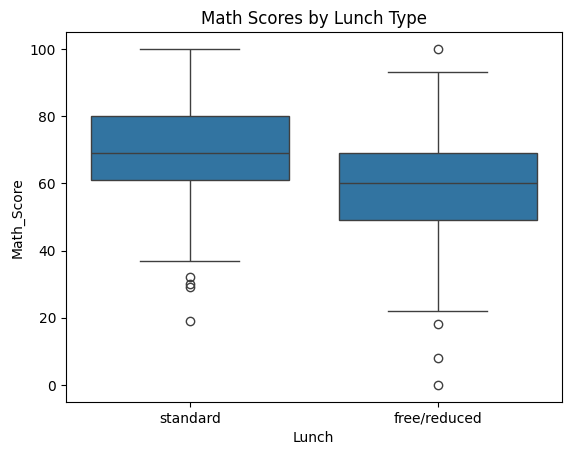

In [202]:
sns.boxplot(data=df, x='Lunch', y='Math_Score')
plt.title('Math Scores by Lunch Type')

The boxplot shows that students with standard lunch have higher math scores than students with free or reduced lunch and the median score is also higher in the standard lunch group

In [203]:
completed = df[df['Test_Preparation_Course'] == 'completed']['Math_Score']
not_completed = df[df['Test_Preparation_Course'] == 'not completed']['Math_Score']

In [204]:
print("Completed:", stats.normaltest(completed))
print("Not Completed:", stats.normaltest(not_completed))

Completed: NormaltestResult(statistic=np.float64(1.6740361326431425), pvalue=np.float64(0.4329997768570043))
Not Completed: NormaltestResult(statistic=np.float64(14.698097497707796), pvalue=np.float64(0.0006432039179011153))


In [205]:
levene_test = stats.levene(completed, not_completed)
print(levene_test)

LeveneResult(statistic=np.float64(0.5330170705114402), pvalue=np.float64(0.4655125071689348))


In [206]:
stats.ttest_ind(completed, not_completed)

TtestResult(statistic=np.float64(5.704616417349102), pvalue=np.float64(1.5359134607147415e-08), df=np.float64(998.0))

The independent t-test showed a significant difference between the two groups so the p-value was less than 0.05 and this means that students who completed the test preparation course had different math scores from students who did not complete it

### Analysis Questions

**1. Does test preparation affect exam scores?**

Yes, test preparation is related to student performance Students who completed the course had higher math scores than students who did not complete it the t-test showed a significant difference between the two groups (p-value < 0.05)

**2. Is there a relationship between reading and writing scores?**

Yes, there is a very strong positive relationship between reading and writing scores the correlation value is 0.95. This means that students with higher reading scores usually have higher writing scores

**3. Does parental education relate to student performance?**

Yes Students whose parents have a master's degree have the highest average scores in all three subjects and Students in the high school or some high school group have the lowest average scores

**4. Do lunch type or gender show differences in scores?**

Yes so Students with standard lunch have higher average scores in all three subjects than students with free or reduced lunch, Male students have higher average math scores while female students have higher average reading and writing scores

---------------------------------------------------------------------

# **Conclusions and Final Delivery**

## 1. Conclusions

### 1.1 Math Score Distribution

The math scores have an almost symmetric distribution with a small negative skew The histogram looks similar to a bell-shaped curve and the normality test shows that the scores are not normally distributed p-value < 0.05

### 1.2 Test Preparation

Students who completed the test preparation course had higher average math scores than students who did not complete it the independent t-test showed a significant difference between the two groups p-value < 0.05

### 1.3 Reading and Writing Relationship

Reading and writing scores have a very strong positive relationship with a correlation of 0.95 so this means that students with higher reading scores usually have higher writing scores

### 1.4 Variation Between Subjects

Writing has the greatest variation among the three subjects based on its standard deviation this means that writing scores are more spread out than math and reading scores

### 1.5 Parental Education and Student Performance

Students whose parents have a master's degree have the highest average scores in all three subjects students in the high school or some high school group have the lowest average scores , This shows a relationship between parental education and student performance

## 2. Practical Recommendations

1. **Test Preparation:** Schools should provide test preparation courses to help students improve their exam performance.

2. **Student Support:** Schools should give extra support to students with low exam scores.

3. **Reading and Writing:** Schools should encourage reading activities because reading and writing scores have a strong relationship.

4. **Parental Education:** Schools should provide more learning support for students who may need extra help at home.

5. **Equal Opportunities:** Schools should make sure that all students have equal access to learning resources and support programs.

## 3. Limitations

1. The dataset contains only 1,000 students, so it may not represent all students.

2. The data does not include information about students' schools, teachers, or study time.

3. The analysis shows relationships between variables, but it does not prove cause and effect.

4. Some results may be affected by differences between student groups.

5. The dataset may not represent the current situation in all schools.

## 4. Suggested Next Steps

1. Collect data from more students and schools.

2. Study other factors that may affect student performance, such as study time and attendance.

3. Compare student performance across different schools.

4. Use more statistical tests to understand the differences between student groups.

5. Develop programs to support students who need academic help.

---------------------------------------------------------------------

In [207]:
import os
os.makedirs('images', exist_ok=True)